In [1]:
from pathlib import Path
import sys
import pandas as pd

project_root = Path.cwd()
if not (project_root / "models").is_dir():
    project_root = project_root.parent

# Put this project first and clear any unrelated installed package named `models`.
sys.path.insert(0, str(project_root))
for module_name in tuple(sys.modules):
    if module_name == "models" or module_name.startswith("models."):
        del sys.modules[module_name]

from models.windows import WindowBuilder, WindowedForecaster

# Load the prepared monthly training data from the project root.
data_path = project_root / "data" / "processed" / "training_data.pkl"
panel = pd.read_pickle(data_path).dropna(subset=["gross_qty"])
print(f"Loaded {len(panel):,} rows from {data_path}")

Loaded 20,309 rows from d:\demond_forcasting\data\processed\training_data.pkl


In [2]:
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from models.quantile import KEYS, LGBMQuantile, NaiveLag1, QuantileForecast
from models.uantile import XGBQuantile
# from models.models_intermittent import IntermittentModel
from models.nhits import NHiTSQuantile
from models.backtest import RollingOrigin, Backtester, assert_no_leakage
from models.evaluation import Evaluator, age_bucket
from models.plots import ForecastPlots

project_root = Path.cwd()          # use the project_root line from your other notebooks if it differs

LEVELS = [0.1, 0.5, 0.8, 0.9, 0.95]
FEATURES = ["year", "month_sin", "month_cos", "time_idx", "range_age_months", "lag_1_gross_qty", "rolling_mean_3", "rolling_mean_6",
            "lag_12_gross_qty", "return_rate_prev_month", "Site", "Brand", "Range"]

project_root = Path.cwd()
if not (project_root / "models").is_dir():
    project_root = project_root.parent

data_path = project_root / "data" / "processed" / "monthly_demand.pkl"
if not data_path.exists():
    alt_path = project_root / "notebooks" / "data" / "processed" / "monthly_demand.pkl"
    if alt_path.exists():
        data_path = alt_path
    else:
        raise FileNotFoundError(f"Could not find monthly_demand.pkl under {project_root}")

dft = pd.read_pickle(data_path)
KEEP = list(dict.fromkeys(FEATURES + ["gross_qty"]))
_missing = [c for c in KEEP if c not in dft.columns]
assert not _missing, f"columns not found in monthly_demand: {_missing}"

panel = dft[KEEP].dropna(subset=["gross_qty"]).reset_index(drop=True)
panel[KEYS] = panel[KEYS].astype(str)
print("rows:", f"{len(panel):,}", "| series:", panel.groupby(KEYS).ngroups, "| months:", int(panel["time_idx"].min()), "to", int(panel["time_idx"].max()))

rows: 20,309 | series: 586 | months: 0 to 41


In [3]:
N_SEEDS = 1          # N-HiTS networks per fold: 1 for a first run, 3 for the final one
FOLDS = RollingOrigin(int(panel["time_idx"].max()), horizon=6, n_folds=4)
MODELS = {
    "naive lag_1": lambda: NaiveLag1(),
    "LightGBM": lambda: LGBMQuantile(LEVELS, FEATURES),
    "XGBoost": lambda: XGBQuantile(LEVELS, FEATURES),
    "N-HiTS": lambda: NHiTSQuantile(LEVELS, window=6, n_seeds=N_SEEDS),
}
print("folds (train up to month ->  validate):", [(c, f"{c + 1}-{c + FOLDS.horizon}") for c in FOLDS.cutoffs])

folds (train up to month ->  validate): [(17, '18-23'), (23, '24-29'), (29, '30-35'), (35, '36-41')]


In [4]:
results, timings, backtests = {}, {}, {}
for _name, _make in MODELS.items():
    _t0 = time.perf_counter()
    backtests[_name] = Backtester(panel, FOLDS)
    results[_name] = backtests[_name].run(_make)
    timings[_name] = time.perf_counter() - _t0
    print(f"{_name}: {timings[_name]:.0f}s")

naive lag_1: 0s
LightGBM: 10s
XGBoost: 42s
N-HiTS: 178s


In [5]:
_last = FOLDS.cutoffs[-1]
for _name in ("naive lag_1", "LightGBM", "XGBoost", "N-HiTS"):
    assert_no_leakage(backtests[_name].fitted[_last], panel, results[_name][_last][0])
    print(_name, ": no leakage")

naive lag_1 : no leakage
LightGBM : no leakage
XGBoost : no leakage
N-HiTS : no leakage


In [6]:
def _average(qfs):
    return QuantileForecast(qfs[0].keys, qfs[0].levels, np.mean([q.values for q in qfs], axis=0))

results_all = {**results, "Average of 3": {c: (results["LightGBM"][c][0], _average([results[n][c][1] for n in ("LightGBM", "XGBoost", "N-HiTS")]))
                                             for c in FOLDS.cutoffs}}

In [7]:
tables = {}
for _c in FOLDS.cutoffs:
    _val = results_all["LightGBM"][_c][0]
    tables[f"months {_c + 1}-{_c + FOLDS.horizon}"] = Evaluator(_val, _val["gross_qty"].to_numpy()).table({n: results_all[n][_c][1] for n in results_all})
per_fold = pd.concat(tables)                                                  # one block per fold
mean_over_folds = per_fold.groupby(level=1).mean().loc[list(results_all)]     # average of the folds
mean_over_folds.round(3)

,MAE,RMSE,WAPE,Bias,WAPE mature (age>=12),WAPE young (age<12),"coverage [P10,P90]",mean pinball,interval score,n_rows
naive lag_1,581.813,2383.668,0.291,-2.081,0.288,0.694,NaN,NaN,NaN,3055.75
LightGBM,513.658,2191.327,0.257,-41.499,0.255,0.600,0.819,171.778,2585.059,3055.75
XGBoost,494.071,2230.568,0.247,-127.930,0.245,0.658,0.789,165.553,2496.248,3055.75
N-HiTS,485.495,1964.591,0.241,-117.883,0.238,0.625,0.848,172.324,2742.231,3055.75
Average of 3,468.584,1987.436,0.234,-95.771,0.232,0.568,0.822,153.275,2255.326,3055.75


In [8]:
tables = {}
for _c in FOLDS.cutoffs:
    _val = results_all["LightGBM"][_c][0]
    tables[f"months {_c + 1}-{_c + FOLDS.horizon}"] = Evaluator(_val, _val["gross_qty"].to_numpy()).table({n: results_all[n][_c][1] for n in results_all})
per_fold = pd.concat(tables)                                                  # one block per fold
mean_over_folds = per_fold.groupby(level=1).mean().loc[list(results_all)]     # average of the folds
mean_over_folds.round(3)

,MAE,RMSE,WAPE,Bias,WAPE mature (age>=12),WAPE young (age<12),"coverage [P10,P90]",mean pinball,interval score,n_rows
naive lag_1,581.813,2383.668,0.291,-2.081,0.288,0.694,NaN,NaN,NaN,3055.75
LightGBM,513.658,2191.327,0.257,-41.499,0.255,0.600,0.819,171.778,2585.059,3055.75
XGBoost,494.071,2230.568,0.247,-127.930,0.245,0.658,0.789,165.553,2496.248,3055.75
N-HiTS,485.495,1964.591,0.241,-117.883,0.238,0.625,0.848,172.324,2742.231,3055.75
Average of 3,468.584,1987.436,0.234,-95.771,0.232,0.568,0.822,153.275,2255.326,3055.75


In [9]:
pd.to_pickle({"results": results, "timings": timings}, project_root / "data" / "processed" / "compare_results.pkl")
print("saved:", (project_root / "data" / "processed" / "compare_results.pkl").stat().st_size // 1024, "KB")

saved: 10916 KB


In [10]:
_lower = ["MAE", "RMSE", "WAPE", "mean pinball"]
winners = {m: mean_over_folds[m].idxmin() for m in _lower}
winners["coverage closest to 0.80"] = (mean_over_folds["coverage [P10,P90]"] - 0.8).abs().idxmin()
print("winners:", winners)
print("seconds per model (all folds):", {k: round(v) for k, v in timings.items()})

winners: {'MAE': 'Average of 3', 'RMSE': 'N-HiTS', 'WAPE': 'Average of 3', 'mean pinball': 'Average of 3', 'coverage closest to 0.80': 'XGBoost'}
seconds per model (all folds): {'naive lag_1': 0, 'LightGBM': 10, 'XGBoost': 42, 'N-HiTS': 178}


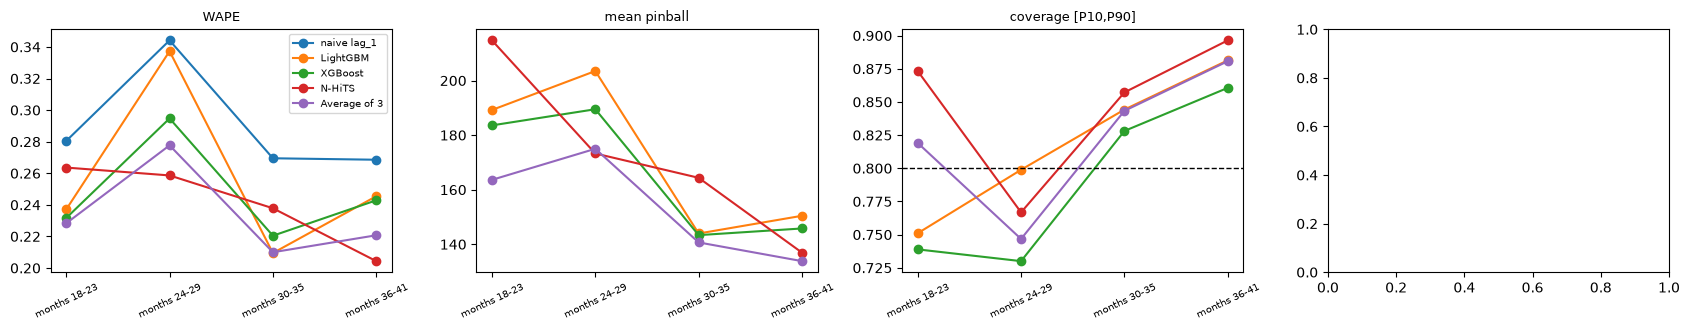

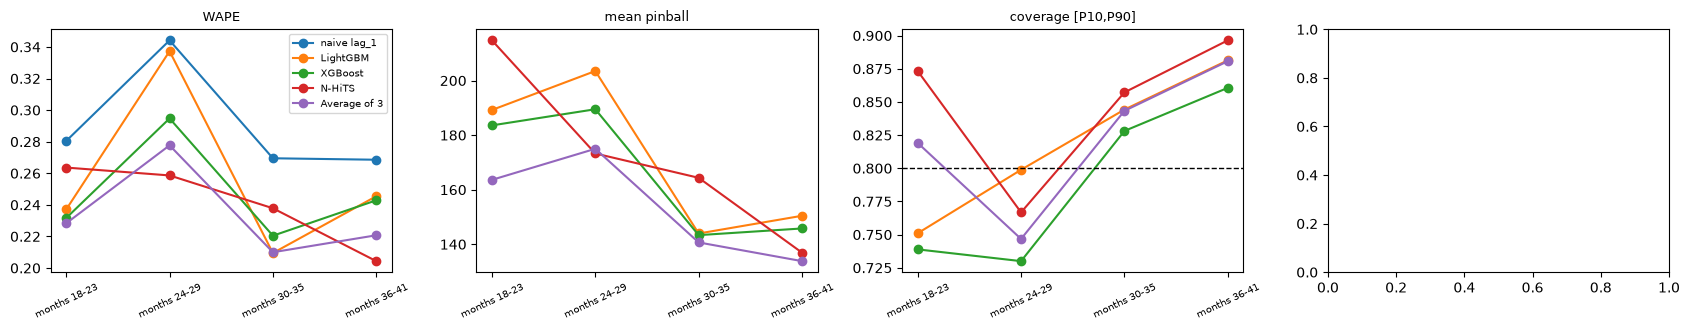

In [11]:
_fig, _axes = plt.subplots(1, 4, figsize=(17, 3.4))
for _ax, _m in zip(_axes, ["WAPE",  "mean pinball", "coverage [P10,P90]"]):
    for _name in results_all:
        _v = [tables[k].loc[_name, _m] for k in tables]
        _ax.plot(range(len(_v)), _v, "o-", label=_name)
    _ax.set_xticks(range(len(tables))); _ax.set_xticklabels(list(tables), rotation=25, fontsize=7); _ax.set_title(_m, fontsize=9)
    if "coverage" in _m:
        _ax.axhline(0.8, color="black", lw=1, ls="--")
_axes[0].legend(fontsize=7)
_fig.tight_layout()
_fig

In [12]:
TIERS = ["small", "medium", "large"]
_parts = []
for _c in FOLDS.cutoffs:
    _val = results_all["LightGBM"][_c][0]
    # a Range's size = its units over the 12 training months before the cutoff (no peeking at validation), cut into thirds
    _hist = panel[(panel["time_idx"] <= _c) & (panel["time_idx"] > _c - 12)]
    _vol = _hist.groupby("Range")["gross_qty"].sum()
    _tier_of = pd.qcut(_vol.rank(method="first"), 3, labels=TIERS).astype(str)
    _label = _val["Range"].map(_tier_of).fillna("no history").to_numpy()
    _ev = Evaluator(_val, _val["gross_qty"].to_numpy())
    for _t in TIERS:
        _tab = _ev.table({n: results_all[n][_c][1] for n in results_all}, eligible=(_label == _t))
        _tab.insert(0, "tier", _t)
        _parts.append(_tab.rename_axis("model").reset_index())
by_tier_folds = pd.concat(_parts, ignore_index=True)

_metrics = [c for c in by_tier_folds.columns if c not in ("model", "tier", "n_rows")]
by_tier = by_tier_folds.groupby(["tier", "model"])[_metrics].mean()                      # average of the four folds
by_tier["n_rows"] = by_tier_folds.groupby(["tier", "model"])["n_rows"].sum()             # rows over all folds
by_tier = by_tier.reindex(pd.MultiIndex.from_product([TIERS, list(results_all)], names=["tier", "model"]))
by_tier.round(3)

MAE      RMSE   WAPE     Bias  WAPE mature (age>=12)  \
tier   model                                                                    
small  naive lag_1    71.584   385.163  0.578  -16.105                  0.546   
       LightGBM       69.364   413.223  0.548  -30.232                  0.520   
       XGBoost        69.277   409.179  0.544  -37.192                  0.520   
       N-HiTS         67.687   397.497  0.531  -33.787                  0.509   
       Average of 3   66.043   400.338  0.519  -33.737                  0.494   
medium naive lag_1   474.566  1475.151  0.385   12.618                  0.383   
       LightGBM      404.710  1174.171  0.327  -18.606                  0.325   
       XGBoost       389.379  1143.280  0.312  -83.009                  0.310   
       N-HiTS        406.405  1217.820  0.324  -64.043                  0.322   
       Average of 3  384.814  1129.267  0.309  -55.219                  0.308   
large  naive lag_1   933.456  3316.200  0.266   -2.642                  0.263   
       LightGBM      830.546  3085.789  0.237  -60.402                  0.235   
       XGBoost       796.958  3150.885  0.227 -205.638                  0.224   
       N-HiTS        767.012  2714.187  0.217 -198.808                  0.215   
       Average of 3  745.271  2775.823  0.212 -154.950                  0.210   

                     WAPE young (age<12)  coverage [P10,P90]  mean pinball  \
tier   model                                                                 
small  naive lag_1                 0.936                 NaN           NaN   
       LightGBM                    0.827               0.919        26.288   
       XGBoost                     0.817               0.899        26.471   
       N-HiTS                      0.739               0.905        26.278   
       Average of 3                0.781               0.899        25.451   
medium naive lag_1                 0.576                 NaN           NaN   
       LightGBM                    0.488               0.780       132.620   
       XGBoost                     0.647               0.750       130.847   
       N-HiTS                      0.617               0.827       139.397   
       Average of 3                0.517               0.792       125.014   
large  naive lag_1                 0.696                 NaN           NaN   
       LightGBM                    0.584               0.790       277.774   
       XGBoost                     0.679               0.755       264.980   
       N-HiTS                      0.636               0.832       274.185   
       Average of 3                0.556               0.800       242.231   

                     interval score  n_rows  
tier   model                                 
small  naive lag_1              NaN    3031  
       LightGBM             441.836    3031  
       XGBoost              447.751    3031  
       N-HiTS               449.911    3031  
       Average of 3         433.307    3031  
medium naive lag_1              NaN    3668  
       LightGBM            1955.041    3668  
       XGBoost             1978.513    3668  
       N-HiTS              2149.901    3668  
       Average of 3        1826.344    3668  
large  naive lag_1              NaN    5520  
       LightGBM            4180.493    5520  
       XGBoost             3964.617    5520  
       N-HiTS              4390.505    5520  
       Average of 3        3540.561    5520

In [13]:
from models.range_view import RangeView

_parts = []
for _c in FOLDS.cutoffs:
    _val = results_all["LightGBM"][_c][0]
    _hist = panel[(panel["time_idx"] <= _c) & (panel["time_idx"] > _c - 12)]
    _vol = _hist.groupby("Range")["gross_qty"].sum()
    _tier_of = pd.qcut(_vol.rank(method="first"), 3, labels=TIERS).astype(str)
    # every model is scored on the SAME series: rows where all models have a forecast
    _ok = ~np.any([np.isnan(results_all[n][_c][1].values).any(axis=1) for n in results_all], axis=0)
    for _name in results_all:
        _qf = results_all[_name][_c][1]
        if not _qf.has(0.1, 0.5, 0.9):
            continue                                              # the naive baseline has no range
        _same = QuantileForecast(_qf.keys, _qf.levels, np.where(_ok[:, None], _qf.values, np.nan))
        _t = RangeView(_val, _same, history=panel, n_draws=500).table().assign(model=_name, fold=_c)
        _t["tier"] = _t["Range"].map(_tier_of).fillna("no history")
        _parts.append(_t)
range_level = pd.concat(_parts, ignore_index=True)
range_level["abs_err"] = (range_level["p50"] - range_level["actual"]).abs()
range_level["width"] = range_level["p90"] - range_level["p10"]
_g = range_level.groupby(["tier", "model"])
range_summary = pd.DataFrame({
    "Ranges": _g["Range"].nunique(), "Range-months": _g.size(),
    "WAPE of totals": _g["abs_err"].sum() / _g["actual"].sum(),
    "bias %": 100 * (_g["p50"].sum() / _g["actual"].sum() - 1),
    "coverage A": _g["inside_A"].mean(), "coverage B": _g["inside_B"].mean(),
    "band width / actual": _g["width"].sum() / _g["actual"].sum()})
range_summary = range_summary.reindex(pd.MultiIndex.from_product([TIERS, [n for n in results_all if n != "naive lag_1"]], names=["tier", "model"]))
range_summary.round(3)

Ranges  Range-months  WAPE of totals  bias %  coverage A  \
tier   model                                                                    
small  LightGBM           4            84           0.423 -19.151       0.488   
       XGBoost            4            84           0.426 -25.217       0.429   
       N-HiTS             4            84           0.390 -25.183       0.476   
       Average of 3       4            84           0.398 -23.047       0.488   
medium LightGBM           4            72           0.160  -0.389       0.292   
       XGBoost            4            72           0.152  -2.310       0.389   
       N-HiTS             4            72           0.179  -3.783       0.417   
       Average of 3       4            72           0.148  -2.104       0.472   
large  LightGBM           4            72           0.138  -3.585       0.375   
       XGBoost            4            72           0.132  -3.968       0.389   
       N-HiTS             4            72           0.158  -6.031       0.333   
       Average of 3       4            72           0.131  -4.588       0.431   

                     coverage B  band width / actual  
tier   model                                          
small  LightGBM           0.857                0.535  
       XGBoost            0.810                0.489  
       N-HiTS             0.869                0.494  
       Average of 3       0.833                0.493  
medium LightGBM           0.903                0.203  
       XGBoost            0.875                0.205  
       N-HiTS             0.903                0.241  
       Average of 3       0.917                0.210  
large  LightGBM           0.917                0.189  
       XGBoost            0.917                0.165  
       N-HiTS             0.833                0.170  
       Average of 3       0.944                0.168

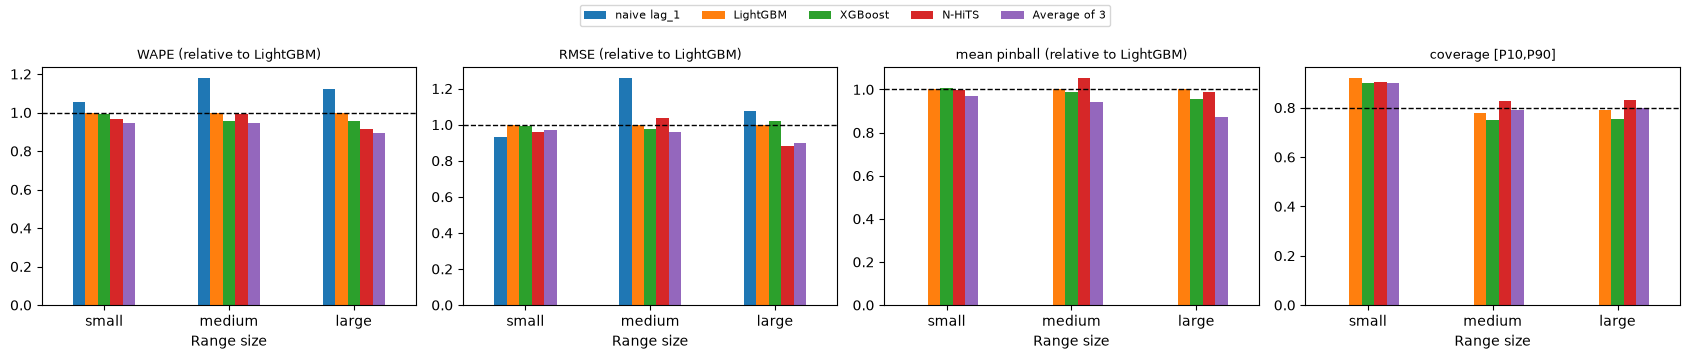

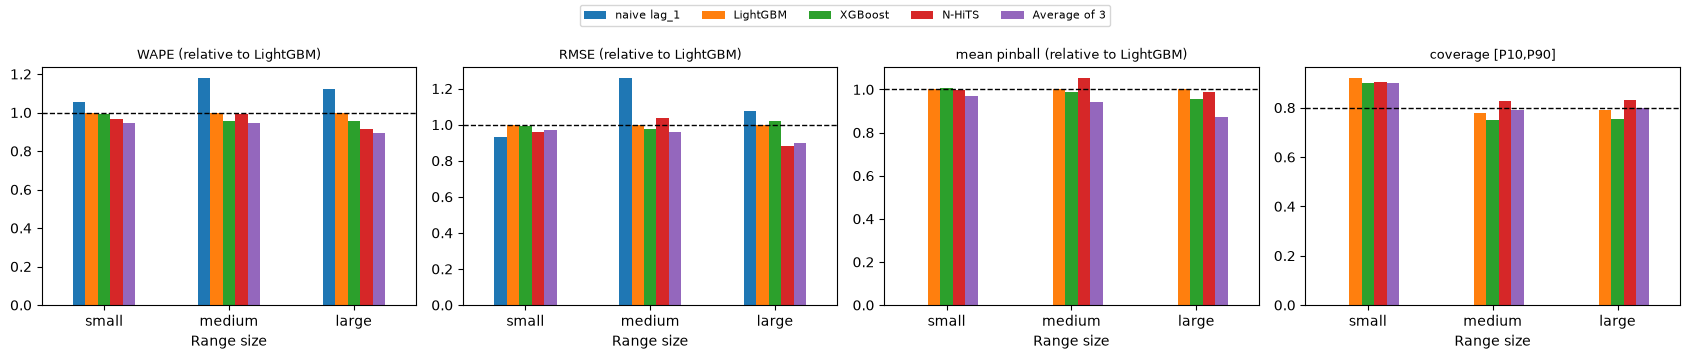

In [14]:
_fig, _axes = plt.subplots(1, 4, figsize=(17, 3.6))
for _ax, _m in zip(_axes, ["WAPE", "RMSE", "mean pinball", "coverage [P10,P90]"]):
    _v = by_tier[_m].unstack("model")[list(results_all)].loc[TIERS]            # rows = tier, columns = model
    if "coverage" not in _m:
        _v = _v.div(_v["LightGBM"], axis=0)                                       # 1.0 = same as LightGBM, below 1.0 = better
    _v.plot.bar(ax=_ax, legend=False, rot=0)
    _ax.axhline(0.8 if "coverage" in _m else 1.0, color="black", lw=1, ls="--")
    _ax.set_title(_m if "coverage" in _m else _m + " (relative to LightGBM)", fontsize=9)
    _ax.set_xlabel("Range size")
_fig.legend(*_axes[0].get_legend_handles_labels(), loc="upper center", ncol=6, fontsize=8)
_fig.tight_layout(rect=(0, 0, 1, 0.92))
_fig

In [15]:
dft.head()

,time_idx,year,month,gross_qty,return_qty,is_filled,Site,Brand,Range,month_sin,month_cos,range_age_months,lag_1_gross_qty,rolling_mean_3,rolling_mean_6,lag_12_gross_qty,return_rate,return_rate_prev_month,display_id
0,0,2022,4,3440.0,0.0,False,53014,50007.0,SC160040,8.660254e-01,-0.500000,0,NaN,NaN,NaN,NaN,0.0,NaN,53014_50007.0_SC160040_2022-04
1,1,2022,5,2430.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,-0.866025,1,3440.0,NaN,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-05
2,2,2022,6,1293.0,0.0,False,53014,50007.0,SC160040,1.224647e-16,-1.000000,2,2430.0,NaN,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-06
3,3,2022,7,1574.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,-0.866025,3,1293.0,2387.666667,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-07
4,4,2022,8,3711.0,0.0,False,53014,50007.0,SC160040,-8.660254e-01,-0.500000,4,1574.0,1765.666667,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-08


In [22]:
import sys
from pathlib import Path
import pandas as pd

# Resolve the repository root whether the notebook starts in the repo or notebooks/.
project_root = Path.cwd().resolve()
if not (project_root / "models").is_dir():
    project_root = project_root.parent
if not (project_root / "models").is_dir():
    raise FileNotFoundError(f"Could not find the project root (models/ folder) from {Path.cwd()}")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
for _m in [m for m in sys.modules if m == "models" or m.startswith("models.")]:
    del sys.modules[_m]

from models.calendar_features import SriLankaCalendar

monthly_path = project_root / "data" / "processed" / "monthly_demand.pkl"
events_path = project_root / "data" / "special_event" / "special_event.csv"
monthly_demand = pd.read_pickle(monthly_path)
events = pd.read_csv(events_path)
print("monthly_demand:", monthly_demand.shape, "| events table:", len(events), "rows")

monthly_demand: (20309, 19) | events table: 16 rows


In [23]:
cal = SriLankaCalendar(events, vat_start=8.0)                       # 8 = the VAT rate (%) in force just before April 2022
calendar_months = cal.monthly(first="2022-04", last="2026-12")      # one row per month; time_idx 0 = April 2022
print("event rows per kind and year (a 0 = not filled in yet):")
print(cal.coverage())
cal.guide()                                                          # what every column means, the method, a numeric example

event rows per kind and year (a 0 = not filled in yet):
year             2022  2023  2024  2025  2026
kind                                         
tax_change          2     0     1     0     0
special_holiday     6     0     1     1     0
school_vacation     0     0     0     5     0


,column,group,meaning,method,example,known on the 1st?
0,time_idx,key,Months since April 2022 (April 2022 = 0),counting,September 2025 = 41,yes
1,days_in_month,calendar,Days in the month,counting,April 2025 = 30,yes
2,weekdays,calendar,Monday-Friday days,counting,April 2025 = 22,yes
3,holidays,calendar,Holidays on any day of the week,lookup in the holidays package,April 2025 = 4,yes
4,holidays_weekday,calendar,Holidays that fall Monday-Friday,lookup + weekday test,"April 2025 = 2 (Mon 14th, Fri 18th)",yes
5,working_days,calendar,Weekdays left after weekday holidays,subtraction: weekdays - holidays_weekday,April 2025: 22 - 2 = 20; April 2023: 20 - 4 = 16,yes
6,poya_days,calendar,Full-moon Poya holidays,match on the holiday name,April 2025 = 1 (the 12th),yes
7,long_weekends,calendar,Breaks of 3+ non-working days that START in th...,run-length detection over weekend + holiday days,April 2025 = 2 (12-14th and 18-20th),yes
8,ramadan_days,moving,Days of Ramadan inside the month,window = the 29 days before Eid al-Fitr; count...,"March 2025 = 29; March 2024 = 19, April 2024 ...","yes, +-1 day (moon sighting)"
9,eid_fitr,moving,1 if Eid al-Fitr is in the month,0/1 flag,March 2025 = 1 (31st); April 2024 = 1 (11th),"yes, +-1 day"


In [24]:
_show = ["2022-05", "2022-06", "2022-08", "2022-09", "2023-12", "2024-01", "2025-03", "2025-04"]
calendar_months.set_index("month").loc[_show, ["time_idx", "working_days", "long_weekends", "ramadan_days", "eid_fitr", "vat_rate", "vat_change_pp", "vat_next_change_pp", "school_vacation_days"]]

,time_idx,working_days,long_weekends,ramadan_days,eid_fitr,vat_rate,vat_change_pp,vat_next_change_pp,school_vacation_days
month,,,,,,,,,
2022-05,1,19,1,2,1,8.0,0.0,0.0,0
2022-06,2,21,0,0,0,12.0,4.0,0.0,0
2022-08,4,22,0,0,0,12.0,0.0,0.0,0
2022-09,5,22,0,0,0,15.0,3.0,0.0,0
2023-12,20,19,1,0,0,15.0,0.0,3.0,0
2024-01,21,21,1,0,0,18.0,3.0,0.0,0
2025-03,35,19,1,29,1,18.0,0.0,0.0,17
2025-04,36,20,2,0,0,18.0,0.0,0.0,9


In [25]:
_new = [c for c in calendar_months.columns if c not in ("month", "time_idx")]
_clash = set(_new) & set(monthly_demand.columns)
assert not _clash, f"these columns already exist in monthly_demand: {_clash}"

monthly_demand_events = monthly_demand.merge(calendar_months.drop(columns="month"), on="time_idx", how="left")

assert len(monthly_demand_events) == len(monthly_demand), "the merge changed the number of rows"
assert not monthly_demand_events[_new].isna().any().any(), "some months have no calendar row"
assert monthly_demand_events[list(monthly_demand.columns)].reset_index(drop=True).equals(monthly_demand.reset_index(drop=True)), "an original column changed"

monthly_demand_events.to_pickle(project_root / "data" / "processed" / "monthly_demand_events.pkl")
calendar_months.to_pickle(project_root / "data" / "processed" / "calendar_months.pkl")
print("saved monthly_demand_events.pkl:", monthly_demand_events.shape, "| original columns:", monthly_demand.shape[1], "| new columns:", len(_new))
print("new columns:", _new)

saved monthly_demand_events.pkl: (20309, 38) | original columns: 19 | new columns: 19
new columns: ['days_in_month', 'weekdays', 'holidays', 'holidays_weekday', 'working_days', 'poya_days', 'long_weekends', 'ramadan_days', 'eid_fitr', 'eid_adha', 'diwali', 'good_friday', 'avurudu', 'christmas', 'school_vacation_days', 'special_holiday_days', 'vat_change_pp', 'vat_next_change_pp', 'vat_rate']


In [27]:
df2 = pd.read_pickle(project_root / "data" / "processed" / "monthly_demand_events.pkl")

In [29]:
df2.head(10)

,time_idx,year,month,gross_qty,return_qty,is_filled,Site,Brand,Range,month_sin,...,eid_adha,diwali,good_friday,avurudu,christmas,school_vacation_days,special_holiday_days,vat_change_pp,vat_next_change_pp,vat_rate
0,0,2022,4,3440.0,0.0,False,53014,50007.0,SC160040,8.660254e-01,...,0,0,1,1,0,0,0,0.0,0.0,8.0
1,1,2022,5,2430.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,...,0,0,0,0,0,0,1,0.0,0.0,8.0
2,2,2022,6,1293.0,0.0,False,53014,50007.0,SC160040,1.224647e-16,...,0,0,0,0,0,0,3,4.0,0.0,12.0
3,3,2022,7,1574.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,...,1,0,0,0,0,0,1,0.0,0.0,12.0
4,4,2022,8,3711.0,0.0,False,53014,50007.0,SC160040,-8.660254e-01,...,0,0,0,0,0,0,0,0.0,0.0,12.0
5,5,2022,9,2255.0,0.0,False,53014,50007.0,SC160040,-1.000000e+00,...,0,0,0,0,0,0,0,3.0,0.0,15.0
6,6,2022,10,2109.0,10.0,False,53014,50007.0,SC160040,-8.660254e-01,...,0,1,0,0,0,0,0,0.0,0.0,15.0
7,7,2022,11,1655.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,...,0,0,0,0,0,0,0,0.0,0.0,15.0
8,8,2022,12,2391.0,0.0,False,53014,50007.0,SC160040,-2.449294e-16,...,0,0,0,0,1,0,1,0.0,0.0,15.0
9,9,2023,1,2005.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,...,0,0,0,0,0,0,0,0.0,0.0,15.0


In [33]:
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve the project root in both script and notebook execution.
try:
    project_root = Path(__file__).resolve().parents[1]
except NameError:
    project_root = Path.cwd().resolve()
if not (project_root / "models").is_dir():
    project_root = project_root.parent
if not (project_root / "models").is_dir():
    raise FileNotFoundError(f"Could not find project root from {Path.cwd()}")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
for _m in [m for m in sys.modules if m == "models" or m.startswith("models.")]:
    del sys.modules[_m]

from models.quantile import KEYS, LGBMQuantile, NaiveLag1
from models.uantile import XGBQuantile
from models.nhits import NHiTSQuantile
from models.backtest import RollingOrigin, Backtester, assert_no_leakage
from models.evaluation import Evaluator
from models.calendar_features import SriLankaCalendar

LEVELS = [0.1, 0.5, 0.8, 0.9, 0.95]
FEATURES = ["year", "month_sin", "month_cos", "time_idx", "range_age_months", "lag_1_gross_qty", "rolling_mean_3", "rolling_mean_6",
            "lag_12_gross_qty", "return_rate_prev_month", "Site", "Brand", "Range"]

# the event columns given to the models: only groups that are known on the 1st of the month and fully filled in
SAFE_GROUPS = ["calendar", "moving", "fixed", "tax_events"]
EVENT_COLS = [c for g in SAFE_GROUPS for c in SriLankaCalendar.GROUPS[g]]

dft = pd.read_pickle(project_root / "data" / "processed" / "monthly_demand_events.pkl")
calendar_months = pd.read_pickle(project_root / "data" / "processed" / "calendar_months.pkl")
KEEP = list(dict.fromkeys(FEATURES + EVENT_COLS + ["gross_qty"]))
_missing = [c for c in KEEP if c not in dft.columns]
assert not _missing, f"columns not found in monthly_demand_events: {_missing}"

panel = dft[KEEP].dropna(subset=["gross_qty"]).reset_index(drop=True)
panel[KEYS] = panel[KEYS].astype(str)

# mean and std of each event column, taken from the CALENDAR table (not from demand), used to standardise them for N-HiTS
event_stats = {c: (float(calendar_months[c].mean()), float(calendar_months[c].std()) if calendar_months[c].std() > 0 else 1.0) for c in EVENT_COLS}
print("rows:", f"{len(panel):,}", "| series:", panel.groupby(KEYS).ngroups, "| months:", int(panel["time_idx"].min()), "to", int(panel["time_idx"].max()))
print(len(EVENT_COLS), "event columns:", EVENT_COLS)

rows: 20,309 | series: 586 | months: 0 to 41
13 event columns: ['working_days', 'holidays_weekday', 'poya_days', 'long_weekends', 'ramadan_days', 'eid_fitr', 'eid_adha', 'diwali', 'good_friday', 'avurudu', 'christmas', 'vat_change_pp', 'vat_next_change_pp']


In [34]:
N_SEEDS = 1          # N-HiTS networks per fold: 1 for a first run, 3 for the final one
FOLDS = RollingOrigin(int(panel["time_idx"].max()), horizon=6, n_folds=4)
MODELS = {
    "naive lag_1": lambda: NaiveLag1(),
    "LightGBM normal": lambda: LGBMQuantile(LEVELS, FEATURES),
    "LightGBM + events": lambda: LGBMQuantile(LEVELS, FEATURES + EVENT_COLS),
    "XGBoost normal": lambda: XGBQuantile(LEVELS, FEATURES),
    "XGBoost + events": lambda: XGBQuantile(LEVELS, FEATURES + EVENT_COLS),
    "N-HiTS normal": lambda: NHiTSQuantile(LEVELS, window=6, n_seeds=N_SEEDS),
    "N-HiTS + events": lambda: NHiTSQuantile(LEVELS, window=6, n_seeds=N_SEEDS, extra=EVENT_COLS, extra_stats=event_stats),
}
print("folds (train up to month ->  validate):", [(c, f"{c + 1}-{c + FOLDS.horizon}") for c in FOLDS.cutoffs])

folds (train up to month ->  validate): [(17, '18-23'), (23, '24-29'), (29, '30-35'), (35, '36-41')]


In [35]:
RECOMPUTE = True      # True = train everything (slow). False = reuse the results saved by the last run
_file = project_root / "data" / "processed" / "compare_events_results.pkl"
backtests = {}
if RECOMPUTE or not _file.exists():
    results, timings = {}, {}
    for _name, _make in MODELS.items():
        _t0 = time.perf_counter()
        backtests[_name] = Backtester(panel, FOLDS)
        results[_name] = backtests[_name].run(_make)
        timings[_name] = time.perf_counter() - _t0
        print(f"{_name}: {timings[_name]:.0f}s")
    pd.to_pickle({"results": results, "timings": timings}, _file)           # saved, so an error later never costs a re-run
else:
    _saved = pd.read_pickle(_file)
    results, timings = _saved["results"], _saved["timings"]
    print("loaded saved results:", list(results))

naive lag_1: 0s
LightGBM normal: 9s
LightGBM + events: 10s
XGBoost normal: 25s
XGBoost + events: 26s
N-HiTS normal: 141s
N-HiTS + events: 34s


In [36]:
_last = FOLDS.cutoffs[-1]
for _name in ("LightGBM + events", "XGBoost + events", "N-HiTS + events"):
    if _name in backtests:
        assert_no_leakage(backtests[_name].fitted[_last], panel, results[_name][_last][0])
        print(_name, ": no leakage")
    else:
        print(_name, ": skipped (results were loaded, models were not saved)")

LightGBM + events : no leakage
XGBoost + events : no leakage
N-HiTS + events : no leakage


In [37]:
tables = {}
for _c in FOLDS.cutoffs:
    _val = results["naive lag_1"][_c][0]
    tables[f"months {_c + 1}-{_c + FOLDS.horizon}"] = Evaluator(_val, _val["gross_qty"].to_numpy()).table({n: results[n][_c][1] for n in results})
per_fold = pd.concat(tables)                                                  # one block per fold
mean_over_folds = per_fold.groupby(level=1).mean().loc[list(results)]
mean_over_folds[["MAE", "RMSE", "WAPE", "Bias", "coverage [P10,P90]", "mean pinball", "interval score"]].round(3)

,MAE,RMSE,WAPE,Bias,"coverage [P10,P90]",mean pinball,interval score
naive lag_1,581.813,2383.668,0.291,-2.081,NaN,NaN,NaN
LightGBM normal,513.658,2191.327,0.257,-41.499,0.819,171.778,2585.059
LightGBM + events,494.399,2194.385,0.247,-61.837,0.814,171.479,2672.370
XGBoost normal,494.071,2230.568,0.247,-127.930,0.789,165.553,2496.248
XGBoost + events,499.588,2257.775,0.250,-103.985,0.785,170.970,2631.154
N-HiTS normal,485.495,1964.591,0.241,-117.883,0.848,172.324,2742.231
N-HiTS + events,796.495,4403.832,0.395,-15.606,0.765,312.975,5406.781


In [38]:
_rows = []
for _fam in ("LightGBM", "XGBoost", "N-HiTS"):
    _a, _b = f"{_fam} normal", f"{_fam} + events"
    _pin = per_fold.xs(_b, level=1)["mean pinball"] / per_fold.xs(_a, level=1)["mean pinball"] - 1      # per fold: negative = events help
    _wape = per_fold.xs(_b, level=1)["WAPE"] / per_fold.xs(_a, level=1)["WAPE"] - 1
    _rows.append({"model": _fam, "pinball change %": 100 * _pin.mean(), "WAPE change %": 100 * _wape.mean(),
                  "folds better by 3%+": int((_pin <= -0.03).sum()), "folds worse by 3%+": int((_pin >= 0.03).sum()),
                  "coverage normal": mean_over_folds.loc[_a, "coverage [P10,P90]"], "coverage + events": mean_over_folds.loc[_b, "coverage [P10,P90]"]})
effect = pd.DataFrame(_rows).set_index("model")
effect.round(3)

,pinball change %,WAPE change %,folds better by 3%+,folds worse by 3%+,coverage normal,coverage + events
model,,,,,,
LightGBM,-0.530,-3.230,2,1,0.819,0.814
XGBoost,2.741,0.961,1,1,0.789,0.785
N-HiTS,82.837,64.216,0,4,0.848,0.765


In [39]:
df2.head(20)

,time_idx,year,month,gross_qty,return_qty,is_filled,Site,Brand,Range,month_sin,...,eid_adha,diwali,good_friday,avurudu,christmas,school_vacation_days,special_holiday_days,vat_change_pp,vat_next_change_pp,vat_rate
0,0,2022,4,3440.0,0.0,False,53014,50007.0,SC160040,8.660254e-01,...,0,0,1,1,0,0,0,0.0,0.0,8.0
1,1,2022,5,2430.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,...,0,0,0,0,0,0,1,0.0,0.0,8.0
2,2,2022,6,1293.0,0.0,False,53014,50007.0,SC160040,1.224647e-16,...,0,0,0,0,0,0,3,4.0,0.0,12.0
3,3,2022,7,1574.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,...,1,0,0,0,0,0,1,0.0,0.0,12.0
4,4,2022,8,3711.0,0.0,False,53014,50007.0,SC160040,-8.660254e-01,...,0,0,0,0,0,0,0,0.0,0.0,12.0
5,5,2022,9,2255.0,0.0,False,53014,50007.0,SC160040,-1.000000e+00,...,0,0,0,0,0,0,0,3.0,0.0,15.0
6,6,2022,10,2109.0,10.0,False,53014,50007.0,SC160040,-8.660254e-01,...,0,1,0,0,0,0,0,0.0,0.0,15.0
7,7,2022,11,1655.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,...,0,0,0,0,0,0,0,0.0,0.0,15.0
8,8,2022,12,2391.0,0.0,False,53014,50007.0,SC160040,-2.449294e-16,...,0,0,0,0,1,0,1,0.0,0.0,15.0
9,9,2023,1,2005.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,...,0,0,0,0,0,0,0,0.0,0.0,15.0
